<a href="https://colab.research.google.com/github/lisbethmesa-droid/toma-de-decisiones/blob/main/PROYECTO_MARSH_toma_de_desiciones.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Especialización en Analítica Estratégica de Datos
### **Toma de Desiciones**
### **Proyecto**

---
**Profesor: German Leonardo Talero**

**Estudiantes:**
- Barrera Gabriela
- Herrera Ivanna
- Mesa Lisbeth

**Institución:** Universidad Pedagógica y Tecnológica de Colombia - UPTC  
**Programa:** Especialización en Analítica Estratégica de Datos  
**Año:** 2026 | Sogamoso, Boyacá

---

**Empresa caso de estudio:** Marsh Colombia  
**Modelos a Implementar:**Modelo de prediccion y montecarlo*

**Dataset:** Pólizas de seguros - predicción de primas y renovación

---

#**Librerias**

In [1]:
from google.colab import drive
import pandas as pd
from pathlib import Path
import numpy as np
from scipy import stats

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Estadística (sesgo/skewness)
from scipy.stats import skew

# División de datos
from sklearn.model_selection import train_test_split

# Preprocesamiento: imputación, escalado, codificación
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PowerTransformer
from sklearn.compose import ColumnTransformer

# Imputación avanzada (MICE)
from sklearn.experimental import enable_iterative_imputer  # necesario para habilitar IterativeImputer
from sklearn.impute import IterativeImputer

# Pipelines
from sklearn.pipeline import Pipeline

# Selección de variables
from sklearn.feature_selection import SelectKBest, f_regression

# Modelos de regresión (los 2 que se comparan)
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

# Modelo base de referencia (para comparar contra algo ingenuo)
from sklearn.dummy import DummyRegressor

# Métricas de evaluación
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

#**Carga de Datos**

In [2]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
  print("No estás en Google Colab. Se omite el montaje de Google Drive.")


Mounted at /content/drive


In [3]:

rutas_posibles = [
    Path("dataset_polizas_sucio.xlsx"),
    Path("./data/dataset_polizas_sucio.xlsx"),
    Path("/content/dataset_polizas_sucio.xlsx"),
    Path("/content/drive/MyDrive/GESTION_ ESTRATEGICA _PROYECTO_ MARSH_/DATA ORIGINAL/dataset_polizas_sucio.xlsx"),
]

ruta_dataset = next((ruta for ruta in rutas_posibles if ruta.exists()), None)

if ruta_dataset is None:
    raise FileNotFoundError(
        "No se encontró el archivo dataset_polizas_sucio.xlsx. "
        "Verifica la ruta exacta en tu Google Drive."
    )

df = pd.read_excel(ruta_dataset)

print(f"Dataset cargado desde: {ruta_dataset}")
print(f"Filas: {df.shape[0]}")
print(f"Columnas: {df.shape[1]}")

Dataset cargado desde: /content/drive/MyDrive/GESTION_ ESTRATEGICA _PROYECTO_ MARSH_/DATA ORIGINAL/dataset_polizas_sucio.xlsx
Filas: 1284
Columnas: 53


In [4]:
df.head()

,id_venta,id_poliza,monto_prima,porcentaje_comision,valor_impuesto,monto_total_venta,fecha_venta,tipo_ramo,fecha_inicio_poliza,fecha_fin_poliza,...,indice_riesgo_combinado,num_tipos_sinistro,es_renovacion,es_cancelada,suma_asegurada_estimada,ramo_alto_riesgo,zona_costera,canal_distribucion,codigo_agente,observaciones
0,VTA0000001,POL000387,1.977802e+08,0.1995,37578244.77,2.353585e+08,2023-12-21,Multirriesgo,NaT,2024-10-11,...,226.525,3,0,0,1977802356,1,1,NaN,NaN,NaN
1,VTA0000002,POL000092,1.717520e+07,0.1629,3263287.33,2.043848e+07,2024-07-01,Manejo,2024-01-14,2025-01-14,...,44.876,2,1,0,171751965,0,0,NaN,NaN,NaN
2,VTA0000005,POL000505,4.917586e+05,0.1793,93434.14,5.851928e+05,2023-04-12,Fianza,2022-12-12,2023-12-12,...,0.715,1,0,0,4917586,0,1,NaN,NaN,NaN
3,VTA0000006,POL000252,1.250678e+06,0.1789,237628.73,1.488306e+06,2024-09-21,Todo Riesgo,2024-04-23,2025-04-23,...,7.890,2,0,0,12506775,1,0,NaN,NaN,NaN
4,VTA0000007,POL000217,3.755291e+06,0.0804,NaN,4.468796e+06,2025-01-27,Automóviles,NaT,2025-01-29,...,11.664,3,0,0,37552910,0,0,NaN,NaN,NaN


# **Clasificacion de Variables**

In [5]:
#Crear diccionario de variables con clasificación
clasificacion = {
    "id_venta": "Identificador",
    "id_poliza": "Identificador",
    "monto_prima": "Cuantitativa continua (Objetivo regresión)",
    "porcentaje_comision": "Cuantitativa continua",
    "valor_impuesto": "Cuantitativa continua",
    "monto_total_venta": "Cuantitativa continua",
    "fecha_venta": "Fecha",
    "tipo_ramo": "Cualitativa nominal",
    "fecha_inicio_poliza": "Fecha",
    "fecha_fin_poliza": "Fecha",
    "codigo_zona_sismica": "Identificador",
    "nivel_riesgo": "Cuantitativa continua",
    "estado_poliza": "Cualitativa nominal",
    "tipo_sector": "Cualitativa nominal",
    "ciudad": "Cualitativa nominal",
    "departamento": "Cualitativa nominal",
    "tamaño_empresa": "Cualitativa ordinal",
    "codigo_divipola": "Identificador",
    "nivel_riesgo_sismico": "Cuantitativa discreta",
    "latitud": "Cuantitativa continua",
    "longitud": "Cuantitativa continua",
    "sector_economico": "Cualitativa nominal",
    "riesgo_sector": "Cuantitativa continua",
    "aseguradora": "Cualitativa nominal",
    "num_sinistros": "Cuantitativa discreta",
    "monto_total_siniestros": "Cuantitativa continua",
    "monto_total_pagado": "Cuantitativa continua",
    "tipos_sinistro": "Cualitativa nominal",
    "sinistros_aprobados": "Cuantitativa discreta",
    "sinistros_rechazados": "Cuantitativa discreta",
    "duracion_poliza_dias": "Cuantitativa discreta",
    "ratio_siniestralidad": "Cuantitativa continua",
    "anio_venta": "Cuantitativa discreta",
    "mes_venta": "Cuantitativa discreta",
    "tiene_sinistro": "Cualitativa binaria (0/1)",
    "log_monto_prima": "Cuantitativa continua",
    "tamaño_empresa_num": "Cualitativa ordinal",
    "antiguedad_meses": "Cuantitativa continua",
    "trimestre_venta": "Cuantitativa discreta",
    "es_temporada_alta": "Cualitativa binaria (0/1)",
    "prima_diaria": "Cuantitativa continua",
    "ratio_aprobacion_sinistros": "Cuantitativa continua",
    "monto_promedio_sinistro": "Cuantitativa continua",
    "indice_riesgo_combinado": "Cuantitativa continua",
    "num_tipos_sinistro": "Cuantitativa discreta",
    "es_renovacion": "Cualitativa binaria (0/1)",
    "es_cancelada": "Cualitativa binaria (0/1)",
    "suma_asegurada_estimada": "Cuantitativa continua",
    "ramo_alto_riesgo": "Cualitativa binaria (0/1)",
    "zona_costera": "Cualitativa binaria (0/1)",
    "canal_distribucion": "Cualitativa nominal",
    "codigo_agente": "Identificador",
    "observaciones": "Cualitativa texto libre"
}

# Crear dataframe con clasificación y tipo detectado
diccionario = pd.DataFrame({
    "Clasificación": [clasificacion.get(col, "Por definir") for col in df.columns],
    "Tipo_detectado": df.dtypes.astype(str)
})

# Mostrar tabla completa
pd.set_option('display.max_rows', None)
display(diccionario)

,Clasificación,Tipo_detectado
id_venta,Identificador,object
id_poliza,Identificador,object
monto_prima,Cuantitativa continua (Objetivo regresión),float64
porcentaje_comision,Cuantitativa continua,float64
valor_impuesto,Cuantitativa continua,float64
monto_total_venta,Cuantitativa continua,float64
fecha_venta,Fecha,datetime64[ns]
tipo_ramo,Cualitativa nominal,object
fecha_inicio_poliza,Fecha,datetime64[ns]
fecha_fin_poliza,Fecha,datetime64[ns]


# **Exploracion de Datos**

In [6]:
# 1. Revisar valores nulos
print("Valores nulos por columna:")
print(df.isnull().sum())

Valores nulos por columna:
id_venta                         0
id_poliza                        0
monto_prima                    103
porcentaje_comision            129
valor_impuesto                  90
monto_total_venta                0
fecha_venta                     52
tipo_ramo                       76
fecha_inicio_poliza             65
fecha_fin_poliza                66
codigo_zona_sismica              0
nivel_riesgo                   154
estado_poliza                   89
tipo_sector                      0
ciudad                           0
departamento                     0
tamaño_empresa                 128
codigo_divipola                  0
nivel_riesgo_sismico             0
latitud                        115
longitud                       115
sector_economico               140
riesgo_sector                  142
aseguradora                     64
num_sinistros                    0
monto_total_siniestros         128
monto_total_pagado             128
tipos_sinistro              

el Dataset si cuenta con variables que contienen nulos

In [7]:
#2.Resumen de nulos
nulos = df.isnull().sum()
nulos_pct = (nulos / len(df) * 100).round(2)
resumen_nulos = pd.DataFrame({'Nulos': nulos, '% del total': nulos_pct})
resumen_nulos = resumen_nulos[resumen_nulos['Nulos'] > 0].sort_values('Nulos', ascending=False)
print("Columnas con valores nulos:", len(resumen_nulos))
display(resumen_nulos)

Columnas con valores nulos: 25


,Nulos,% del total
observaciones,1284,100.00
canal_distribucion,1284,100.00
codigo_agente,1284,100.00
ratio_siniestralidad,179,13.94
antiguedad_meses,168,13.08
nivel_riesgo,154,11.99
tipos_sinistro,149,11.60
riesgo_sector,142,11.06
sector_economico,140,10.90
porcentaje_comision,129,10.05


en este resumen identificamos que se encontraron 25 variables que presentan nulos y cuanto es el porcentaje que representan para cada variable

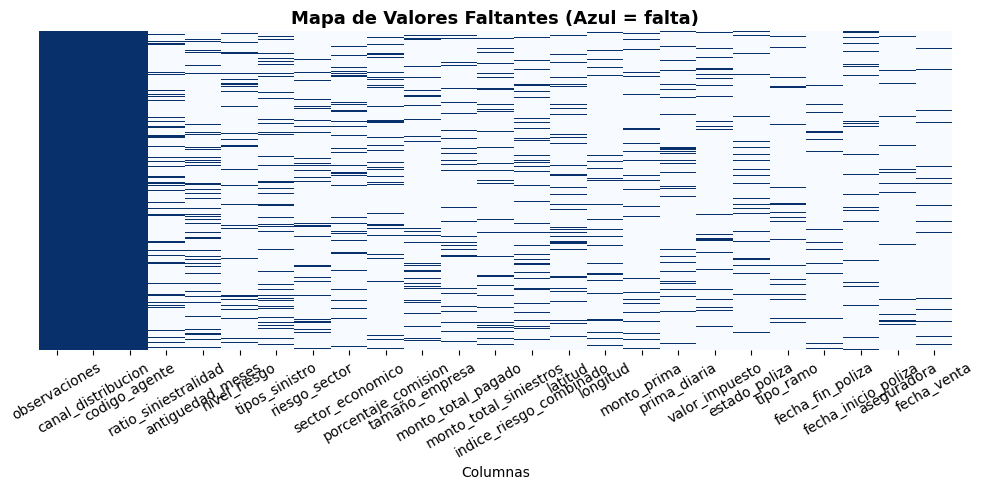

In [8]:
# 3. Mapa visual de nulos
cols_con_nulos = resumen_nulos.index.tolist()
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(df[cols_con_nulos].isnull(), cbar=False, cmap='Blues', yticklabels=False, ax=ax)
ax.set_title('Mapa de Valores Faltantes (Azul = falta)', fontsize=13, fontweight='bold')
ax.set_xlabel('Columnas')
ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

In [9]:
#4. Valores duplicados
print("Duplicados:", df.duplicated().sum())

Duplicados: 9


identificamos que la data presenta pocos duplicados

In [10]:
#5. espacios en blanco
espacios_df = df.apply(lambda col: col.astype(str).str.strip() == '')
print("Espacios o celdas vacías detectados por columna:")
print(espacios_df.sum())

Espacios o celdas vacías detectados por columna:
id_venta                      0
id_poliza                     0
monto_prima                   0
porcentaje_comision           0
valor_impuesto                0
monto_total_venta             0
fecha_venta                   0
tipo_ramo                     0
fecha_inicio_poliza           0
fecha_fin_poliza              0
codigo_zona_sismica           0
nivel_riesgo                  0
estado_poliza                 0
tipo_sector                   0
ciudad                        0
departamento                  0
tamaño_empresa                0
codigo_divipola               0
nivel_riesgo_sismico          0
latitud                       0
longitud                      0
sector_economico              0
riesgo_sector                 0
aseguradora                   0
num_sinistros                 0
monto_total_siniestros        0
monto_total_pagado            0
tipos_sinistro                0
sinistros_aprobados           0
sinistros_rechazados   

identificamos que la data no presenta nungun espacio dentro de sus variables

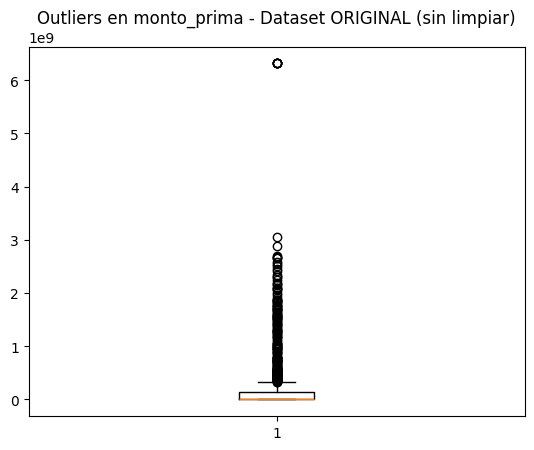

Valores nulos en monto_prima (original): 103
Valor máximo original: 6,314,141,175.00


In [11]:
#6. Visualizar outliers en monto_prima (dataset CRUDO, sin limpiar)
plt.boxplot(df["monto_prima"].dropna())
plt.title("Outliers en monto_prima - Dataset ORIGINAL (sin limpiar)")
plt.show()

print(f"Valores nulos en monto_prima (original): {df['monto_prima'].isnull().sum()}")
print(f"Valor máximo original: {df['monto_prima'].max():,.2f}")

#**Limpieza de Datos**

In [12]:
# Preparación creacion del data limpio
df.columns = df.columns.str.strip()
dfLimpieza = df.copy()

In [13]:
#1 . Eliminar columnas 100% vacías
cols_vacias = dfLimpieza.columns[dfLimpieza.isnull().mean() == 1.0].tolist()
print(f"Columnas eliminadas (100% nulas): {cols_vacias}")
dfLimpieza = dfLimpieza.drop(columns=cols_vacias)

Columnas eliminadas (100% nulas): ['canal_distribucion', 'codigo_agente', 'observaciones']


se decide eliminar esas variables ya que para el analisis no son requeridas y solo van a causar confusion al momento del analisis y de la aplicacion del modelo

In [14]:
# 2. Eliminar duplicados
n_dup = dfLimpieza.duplicated().sum()
print(f"Filas duplicadas eliminadas: {n_dup}")
dfLimpieza = dfLimpieza.drop_duplicates().reset_index(drop=True)

Filas duplicadas eliminadas: 9


se decide eliminar los duplicados ya identificados ya que para la realizacion del analisis estos no son considerados importantes y se hace para evitar distorsion en los resultados

In [15]:
# 3. Limpiar espacios en texto
cols_texto = dfLimpieza.select_dtypes(include='object').columns
for col in cols_texto:
    dfLimpieza[col] = dfLimpieza[col].str.strip()

if 'ciudad' in dfLimpieza.columns:
    dfLimpieza['ciudad'] = dfLimpieza['ciudad'].str.title()

print(f"Espacios eliminados en {len(cols_texto)} columnas de texto: {list(cols_texto)}")

Espacios eliminados en 11 columnas de texto: ['id_venta', 'id_poliza', 'tipo_ramo', 'estado_poliza', 'tipo_sector', 'ciudad', 'departamento', 'tamaño_empresa', 'sector_economico', 'aseguradora', 'tipos_sinistro']


In [16]:
# 4. Tratamiento de nulos "no aplica" (estructurales)
if 'tipos_sinistro' in dfLimpieza.columns and 'num_sinistros' in dfLimpieza.columns:
    mask_sin_siniestro = dfLimpieza['num_sinistros'] == 0
    dfLimpieza.loc[mask_sin_siniestro, 'tipos_sinistro'] = dfLimpieza.loc[mask_sin_siniestro, 'tipos_sinistro'].fillna('Sin siniestro')
    dfLimpieza['tipos_sinistro'] = dfLimpieza['tipos_sinistro'].fillna('No registrado')
    print(f"'tipos_sinistro' tratado: {mask_sin_siniestro.sum()} marcados como 'Sin siniestro'")
else:
    print("Columnas 'tipos_sinistro' o 'num_sinistros' no encontradas — se omite este paso")

'tipos_sinistro' tratado: 50 marcados como 'Sin siniestro'


se decide reemplazar los valores que presenta la variable tipos_siniestro por la etiqueta 'Sin siniestro' conservando asi la informacion y garantizando un analisis mas representativo

#**Imputaciones**

In [17]:
# 5. Imputar categóricas con moda
cols_categoricas_imputar = ['tipo_ramo', 'estado_poliza', 'sector_economico', 'tamaño_empresa', 'aseguradora']
for col in cols_categoricas_imputar:
    if col in dfLimpieza.columns:
        n_nulos_antes = dfLimpieza[col].isnull().sum()
        moda = dfLimpieza[col].mode()[0]
        dfLimpieza[col] = dfLimpieza[col].fillna(moda)
        print(f"{col}: {n_nulos_antes} nulos imputados con moda '{moda}'")

tipo_ramo: 76 nulos imputados con moda 'Automóviles'
estado_poliza: 89 nulos imputados con moda 'Vigente'
sector_economico: 140 nulos imputados con moda 'Suministro de electricidad, gas, vapor y aire acondicionado'
tamaño_empresa: 127 nulos imputados con moda 'Pequeña'
aseguradora: 64 nulos imputados con moda 'HDI'


In [18]:
# 6. Imputar numéricas con mediana
cols_num_mediana = [
    'monto_prima', 'porcentaje_comision', 'valor_impuesto',
    'nivel_riesgo', 'latitud', 'longitud', 'riesgo_sector',
    'ratio_siniestralidad', 'monto_total_siniestros', 'monto_total_pagado',
    'antiguedad_meses', 'indice_riesgo_combinado', 'prima_diaria'
]
for col in cols_num_mediana:
    if col in dfLimpieza.columns:
        n_nulos_antes = dfLimpieza[col].isnull().sum()
        mediana = dfLimpieza[col].median()
        dfLimpieza[col] = dfLimpieza[col].fillna(mediana)
        print(f"{col}: {n_nulos_antes} nulos imputados con mediana {mediana:.2f}")

monto_prima: 102 nulos imputados con mediana 13034790.04
porcentaje_comision: 127 nulos imputados con mediana 0.15
valor_impuesto: 89 nulos imputados con mediana 2404055.40
nivel_riesgo: 153 nulos imputados con mediana 8.38
latitud: 115 nulos imputados con mediana 5.07
longitud: 115 nulos imputados con mediana -75.45
riesgo_sector: 141 nulos imputados con mediana 1.30
ratio_siniestralidad: 178 nulos imputados con mediana 7.42
monto_total_siniestros: 127 nulos imputados con mediana 140456239.90
monto_total_pagado: 127 nulos imputados con mediana 73952547.06
antiguedad_meses: 166 nulos imputados con mediana 24.30
indice_riesgo_combinado: 115 nulos imputados con mediana 31.55
prima_diaria: 102 nulos imputados con mediana 36571.86


In [19]:
#7. Imputar fechas
cols_fecha = ['fecha_venta', 'fecha_inicio_poliza', 'fecha_fin_poliza']
for col in cols_fecha:
    if col in dfLimpieza.columns:
        dfLimpieza[col] = pd.to_datetime(dfLimpieza[col], errors='coerce')
        n_nulos_antes = dfLimpieza[col].isnull().sum()
        dfLimpieza[col] = dfLimpieza[col].fillna(dfLimpieza[col].median())
        print(f"{col}: {n_nulos_antes} nulos imputados con fecha mediana")

fecha_venta: 51 nulos imputados con fecha mediana
fecha_inicio_poliza: 64 nulos imputados con fecha mediana
fecha_fin_poliza: 64 nulos imputados con fecha mediana


se decide imputar las fechas por la mediana manteniendo el mismo criterio estadistico a variables numericas, evitando intriducir un sesgo hacia periodos especificos del dataset.

#**Deteccion y Tratamiento de Outlers**

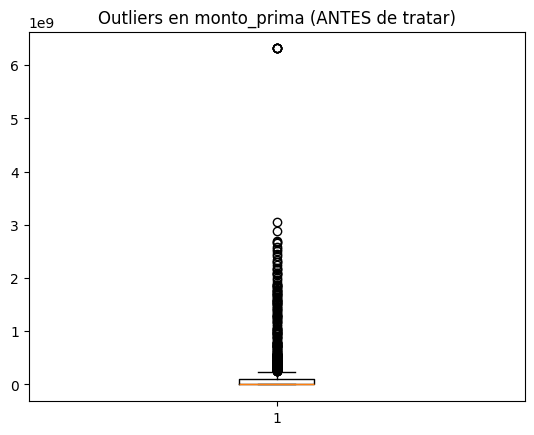

Dimensiones del dataset: (1275, 50)


In [20]:
#8. Visualizar outliers en monto_prima
plt.boxplot(dfLimpieza["monto_prima"])
plt.title("Outliers en monto_prima (ANTES de tratar)")
plt.show()

print(f"Dimensiones del dataset: {dfLimpieza.shape}")

Outliers detectados en monto_prima: 218


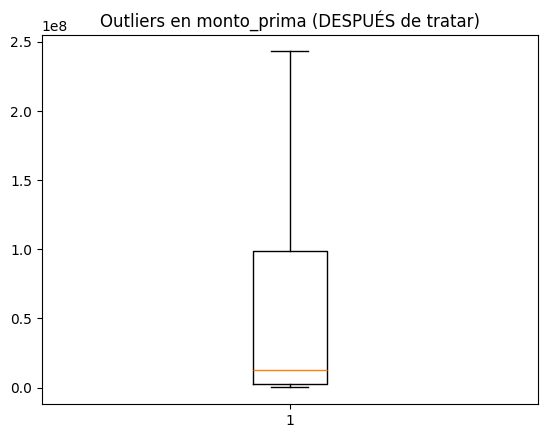

Dimensiones finales del dataset: (1275, 50)


In [21]:
#8.1 Tratamiento de outliers en monto_prima (IQR - capping)
q1, q3 = dfLimpieza['monto_prima'].quantile([0.25, 0.75])
iqr = q3 - q1
lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
n_outliers = ((dfLimpieza['monto_prima'] < lim_inf) | (dfLimpieza['monto_prima'] > lim_sup)).sum()
print(f"Outliers detectados en monto_prima: {n_outliers}")

dfLimpieza['monto_prima'] = dfLimpieza['monto_prima'].clip(lower=lim_inf, upper=lim_sup)

plt.boxplot(dfLimpieza["monto_prima"])
plt.title("Outliers en monto_prima (DESPUÉS de tratar)")
plt.show()

print(f"Dimensiones finales del dataset: {dfLimpieza.shape}")

In [22]:
# 9. Detección de outliers en otras variables clave (sin capping, solo se documentan)
vars_revisar = ['ratio_siniestralidad', 'monto_total_siniestros', 'monto_total_pagado']
vars_revisar = [v for v in vars_revisar if v in dfLimpieza.columns]
print("\nOutliers detectados en otras variables (no tratados, se documentan como limitación):")
for col in vars_revisar:
    q1c, q3c = dfLimpieza[col].quantile([0.25, 0.75])
    iqrc = q3c - q1c
    lim_infc, lim_supc = q1c - 1.5*iqrc, q3c + 1.5*iqrc
    n_out = ((dfLimpieza[col] < lim_infc) | (dfLimpieza[col] > lim_supc)).sum()
    print(f"  {col}: {n_out} outliers")


Outliers detectados en otras variables (no tratados, se documentan como limitación):
  ratio_siniestralidad: 162 outliers
  monto_total_siniestros: 153 outliers
  monto_total_pagado: 188 outliers


#**Validacion de Tipos de Datos**

In [23]:
# 10.Validación y corrección de tipos de datos
cols_codigo_texto = ['codigo_zona_sismica', 'codigo_divipola']
for col in cols_codigo_texto:
    if col in dfLimpieza.columns:
        dfLimpieza[col] = dfLimpieza[col].astype(str)

for col in cols_categoricas_imputar:
    if col in dfLimpieza.columns:
        dfLimpieza[col] = dfLimpieza[col].astype('category')

print(f"Tipos corregidos — códigos a texto: {cols_codigo_texto}")
print(f"Tipos corregidos — categóricas a 'category': {cols_categoricas_imputar}")

Tipos corregidos — códigos a texto: ['codigo_zona_sismica', 'codigo_divipola']
Tipos corregidos — categóricas a 'category': ['tipo_ramo', 'estado_poliza', 'sector_economico', 'tamaño_empresa', 'aseguradora']


In [24]:
# 11. Segunda pasada de duplicados (tras imputación)
n_dup_post = dfLimpieza.duplicated().sum()
dfLimpieza = dfLimpieza.drop_duplicates().reset_index(drop=True)

print(f"\nDimensiones finales del dataset: {dfLimpieza.shape}")
print(f"Nulos restantes: {dfLimpieza.isnull().sum().sum()}")
print(f"Duplicados restantes: {dfLimpieza.duplicated().sum()}")



Dimensiones finales del dataset: (1274, 50)
Nulos restantes: 0
Duplicados restantes: 0


#**Estadisticos Descriptivos profiling**

In [25]:
#12. Estadísticos descriptivos numéricos
desc_num = dfLimpieza.describe().T
desc_num['mediana'] = dfLimpieza.median(numeric_only=True)
desc_num['asimetria'] = dfLimpieza.skew(numeric_only=True)
desc_num['curtosis'] = dfLimpieza.kurt(numeric_only=True)
display(desc_num.round(2))

,count,mean,min,25%,50%,75%,max,std,mediana,asimetria,curtosis
monto_prima,1274.0,66239753.061641,92222.52,2835759.355,13034790.04,99088547.475,242935773.435,92344252.703037,1.303479e+07,1.18,-0.36
porcentaje_comision,1274.0,0.151569,0.0803,0.1197,0.15335,0.1817,0.2199,0.038335,1.500000e-01,-0.09,-1.02
valor_impuesto,1274.0,37464280.93852,17522.28,504693.91,2404055.395,18826824.0225,581643203.51,88831444.574692,2.404055e+06,3.21,10.47
monto_total_venta,1274.0,248176327.452606,109744.8,2934366.31,15485147.195,159232850.885,3642923222.0,565899759.830149,1.548515e+07,3.13,9.91
fecha_venta,1274,2023-12-23 06:27:41.538461696,2022-01-08 00:00:00,2023-04-02 06:00:00,2023-12-22 00:00:00,2024-09-12 18:00:00,2025-12-21 00:00:00,NaN,NaN,NaN,NaN
fecha_inicio_poliza,1274,2023-07-30 07:02:43.893249536,2021-11-29 00:00:00,2022-11-09 12:00:00,2023-07-26 00:00:00,2024-04-09 18:00:00,2025-11-30 00:00:00,NaN,NaN,NaN,NaN
fecha_fin_poliza,1274,2024-08-03 13:19:07.252747264,2022-11-30 00:00:00,2023-11-29 06:00:00,2024-08-03 00:00:00,2025-04-14 12:00:00,2026-12-01 00:00:00,NaN,NaN,NaN,NaN
nivel_riesgo,1274.0,20.819305,0.38,3.9175,8.385,21.45,385.54,34.387517,8.380000e+00,4.08,25.36
nivel_riesgo_sismico,1274.0,2.983516,1.0,2.0,3.0,4.0,5.0,1.437532,3.000000e+00,0.09,-1.32
latitud,1274.0,5.165607,-4.215,3.01525,5.07,7.09,11.544,2.879108,5.070000e+00,0.04,-0.00


In [26]:
#13. Estadísticos descriptivos categóricos
cat_cols = dfLimpieza.select_dtypes(include='object').columns
for col in cat_cols:
    print(f"\n--- {col} ---")
    print(f"Valores únicos: {dfLimpieza[col].nunique()}")
    print(dfLimpieza[col].value_counts().head(10))


--- id_venta ---
Valores únicos: 1274
id_venta
VTA0001410    1
VTA0000001    1
VTA0000002    1
VTA0000005    1
VTA0000006    1
VTA0000007    1
VTA0000008    1
VTA0000010    1
VTA0000011    1
VTA0000012    1
Name: count, dtype: int64

--- id_poliza ---
Valores únicos: 468
id_poliza
POL000505    9
POL000508    7
POL000425    7
POL000292    7
POL000274    7
POL000382    6
POL000370    6
POL000484    6
POL000028    6
POL000300    6
Name: count, dtype: int64

--- codigo_zona_sismica ---
Valores únicos: 87
codigo_zona_sismica
52356    42
25899    34
68001    34
52001    33
85001    32
5088     30
52418    27
15759    27
5615     27
52612    24
Name: count, dtype: int64

--- tipo_sector ---
Valores únicos: 18
tipo_sector
D    115
G    114
O    101
B     82
F     75
I     74
M     74
Q     74
H     72
J     70
Name: count, dtype: int64

--- ciudad ---
Valores únicos: 87
ciudad
Ipiales        42
Zipaquirá      34
Bucaramanga    34
Pasto          33
Yopal          32
Bello          30
La Unión 

#**Transformacion**

In [27]:
# 14. Codificación ordinal y nuevas variables (Feature Engineering)
orden_tamano = {'Microempresa': 1, 'Pequeña': 2, 'Mediana': 3, 'Grande': 4, 'Corporativo': 5}
if 'tamaño_empresa' in dfLimpieza.columns:
    dfLimpieza['tamaño_empresa_num'] = dfLimpieza['tamaño_empresa'].map(orden_tamano)

print("Variable creada: tamaño_empresa_num")


Variable creada: tamaño_empresa_num


In [28]:
dfLimpieza['tamaño_empresa_num'] = dfLimpieza['tamaño_empresa_num'].astype('int64')

In [29]:
# 15. Normalización de formatos categóricos
for col in ['tipo_ramo', 'sector_economico', 'aseguradora']:
    if col in dfLimpieza.columns:
        dfLimpieza[col] = dfLimpieza[col].astype(str).str.strip().str.title()

print("Formatos normalizados en variables categóricas clave")

Formatos normalizados en variables categóricas clave


In [30]:
# 16. Agregación de métricas clave
print("\n" + "="*60)
print("AGREGACIÓN DE MÉTRICAS CLAVE")
print("="*60)

metricas_ramo = dfLimpieza.groupby('tipo_ramo')['monto_prima'].agg(['mean', 'median', 'count']).round(0)
metricas_ramo.columns = ['prima_promedio', 'prima_mediana', 'num_polizas']
print("\nMétricas por Tipo de Ramo:")
display(metricas_ramo.sort_values('prima_promedio', ascending=False))

if 'ratio_siniestralidad' in dfLimpieza.columns:
    metricas_tamano = dfLimpieza.groupby('tamaño_empresa')['ratio_siniestralidad'].mean().round(2)
    print("\nRatio de Siniestralidad Promedio por Tamaño de Empresa:")
    print(metricas_tamano)


AGREGACIÓN DE MÉTRICAS CLAVE

Métricas por Tipo de Ramo:


,prima_promedio,prima_mediana,num_polizas
tipo_ramo,,,
Rc General,89339808.0,58323123.0,52
Multirriesgo,84754013.0,15868619.0,51
Soat,84163270.0,16210085.0,88
Fianza,82818036.0,13395460.0,104
Incendio Y Aliados,74592039.0,13034790.0,93
Transporte,74578069.0,25943389.0,98
Terremoto,66268839.0,17046220.0,53
Automóviles,64008673.0,12440467.0,198
Vida Grupo,62625734.0,10953914.0,90



Ratio de Siniestralidad Promedio por Tamaño de Empresa:
tamaño_empresa
Corporativo      3.77
Grande           6.42
Mediana         12.55
Microempresa    42.91
Pequeña         22.41
Name: ratio_siniestralidad, dtype: float64


/tmp/ipykernel_888/3571019350.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  metricas_tamano = dfLimpieza.groupby('tamaño_empresa')['ratio_siniestralidad'].mean().round(2)


In [ ]:
# 17. Identificación de variables para codificación (se aplica formalmente en el Pipeline de modelado)
cols_a_codificar = ['tipo_ramo', 'tamaño_empresa', 'sector_economico']
cols_a_codificar = [c for c in cols_a_codificar if c in dfLimpieza.columns]
print(f"\nVariables identificadas para codificación (One-Hot Encoding): {cols_a_codificar}")
print("Esta codificación se aplicará formalmente dentro del Pipeline de modelado.")


Variables identificadas para codificación (One-Hot Encoding): ['tipo_ramo', 'tamaño_empresa', 'sector_economico']
Esta codificación se aplicará formalmente dentro del Pipeline de modelado.


#**EDA**

In [32]:
# 18. Configuración de colores corporativos
AZUL, AZUL2, AZUL3 = "#1F4E79", "#2E75B6", "#9DC3E6"
AMARILLO, ROJO, VERDE = "#F4B942", "#C0392B", "#1E8449"
sns.set_theme(style="whitegrid")

/tmp/ipykernel_888/3692599908.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="tamaño_empresa", y="monto_prima", data=dfLimpieza, order=orden_t, palette="Blues", ax=ax)


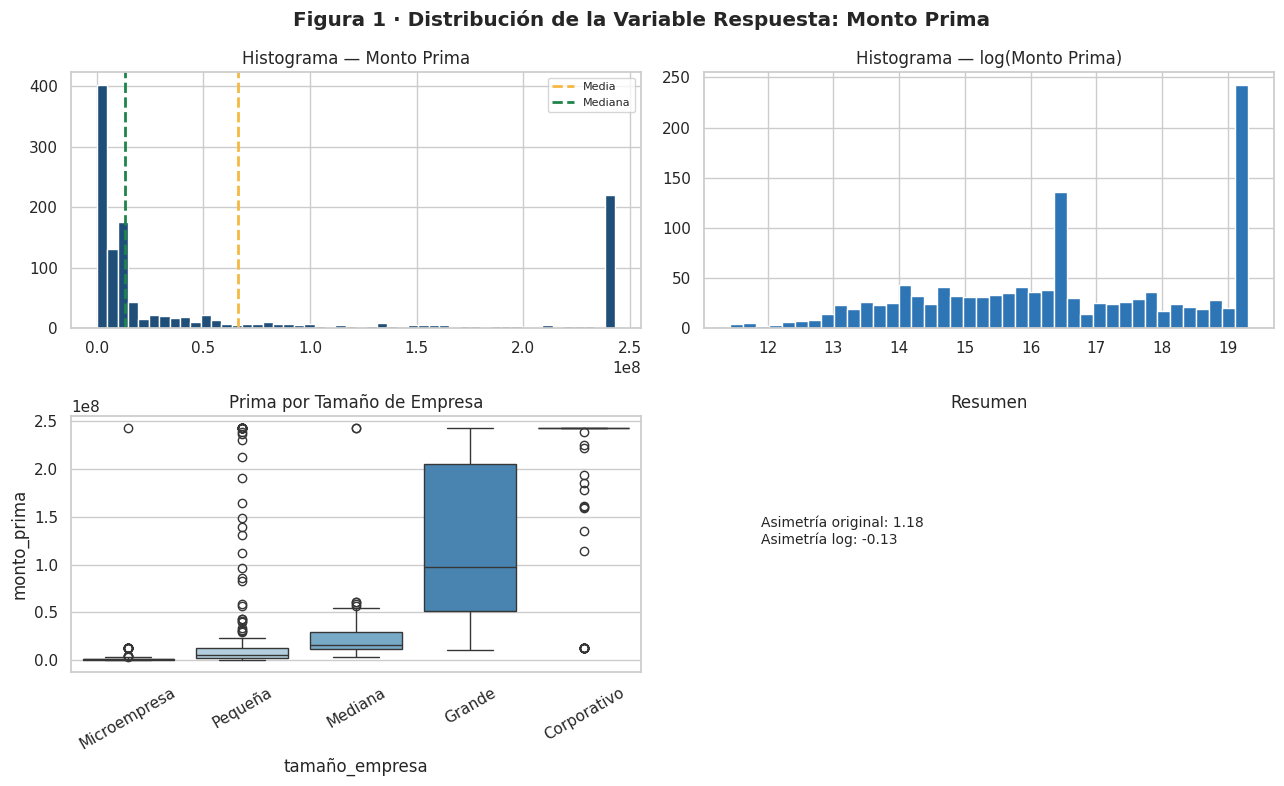

In [33]:
# 19. Figura 1: Distribución de monto_prima
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
fig.suptitle("Figura 1 · Distribución de la Variable Respuesta: Monto Prima", fontweight="bold")

ax = axes[0,0]
ax.hist(dfLimpieza["monto_prima"], bins=50, color=AZUL, edgecolor="white")
ax.set_title("Histograma — Monto Prima")
ax.axvline(dfLimpieza["monto_prima"].mean(), color=AMARILLO, lw=2, ls="--", label="Media")
ax.axvline(dfLimpieza["monto_prima"].median(), color=VERDE, lw=2, ls="--", label="Mediana")
ax.legend(fontsize=8)

ax = axes[0,1]
log_p = np.log1p(dfLimpieza["monto_prima"])
ax.hist(log_p, bins=40, color=AZUL2, edgecolor="white")
ax.set_title("Histograma — log(Monto Prima)")

ax = axes[1,0]
orden_t = [t for t in ["Microempresa","Pequeña","Mediana","Grande","Corporativo"] if t in dfLimpieza["tamaño_empresa"].unique()]
sns.boxplot(x="tamaño_empresa", y="monto_prima", data=dfLimpieza, order=orden_t, palette="Blues", ax=ax)
ax.set_title("Prima por Tamaño de Empresa")
ax.tick_params(axis="x", rotation=30)

ax = axes[1,1]
ax.axis("off")
ax.text(0.1, 0.5, f"Asimetría original: {dfLimpieza['monto_prima'].skew():.2f}\nAsimetría log: {log_p.skew():.2f}", fontsize=10)
ax.set_title("Resumen")

plt.tight_layout()
plt.savefig("fig1_distribucion.png", dpi=150)
plt.show()

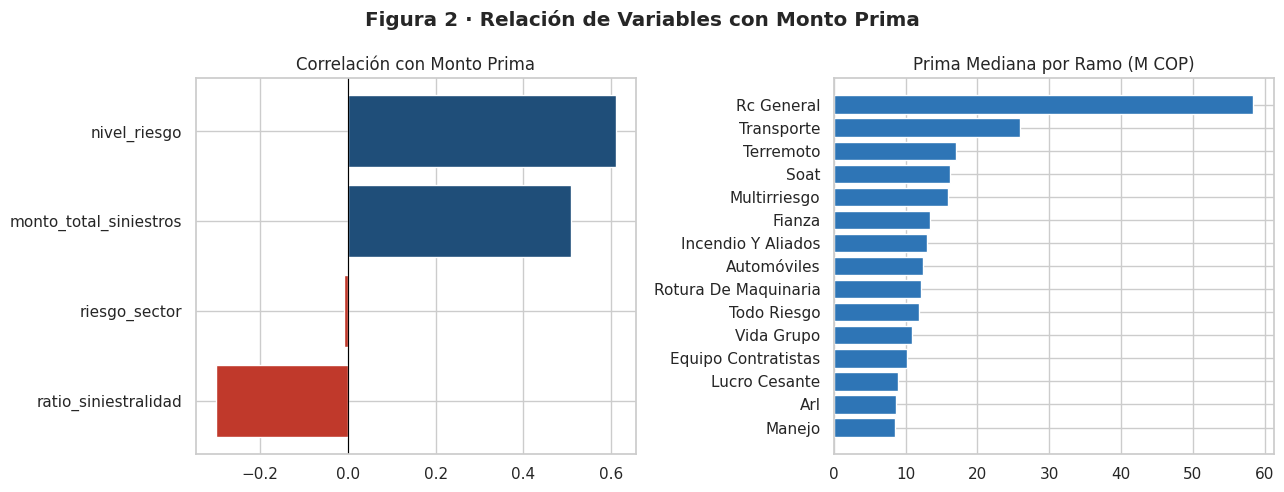

In [34]:
# 20. Figura 2: Correlaciones con monto_prima
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle("Figura 2 · Relación de Variables con Monto Prima", fontweight="bold")

cols_c = [c for c in ["nivel_riesgo","monto_total_siniestros","riesgo_sector","ratio_siniestralidad"] if c in dfLimpieza.columns]
corr_v = dfLimpieza[cols_c + ["monto_prima"]].corr()["monto_prima"].drop("monto_prima").sort_values()
colores = [ROJO if v < 0 else AZUL for v in corr_v.values]
axes[0].barh(corr_v.index, corr_v.values, color=colores)
axes[0].set_title("Correlación con Monto Prima")
axes[0].axvline(0, color="black", lw=0.8)

ramo_med = dfLimpieza.groupby("tipo_ramo")["monto_prima"].median().sort_values()
axes[1].barh(ramo_med.index, ramo_med.values/1e6, color=AZUL2)
axes[1].set_title("Prima Mediana por Ramo (M COP)")

plt.tight_layout()
plt.savefig("fig2_correlaciones.png", dpi=150)
plt.show()

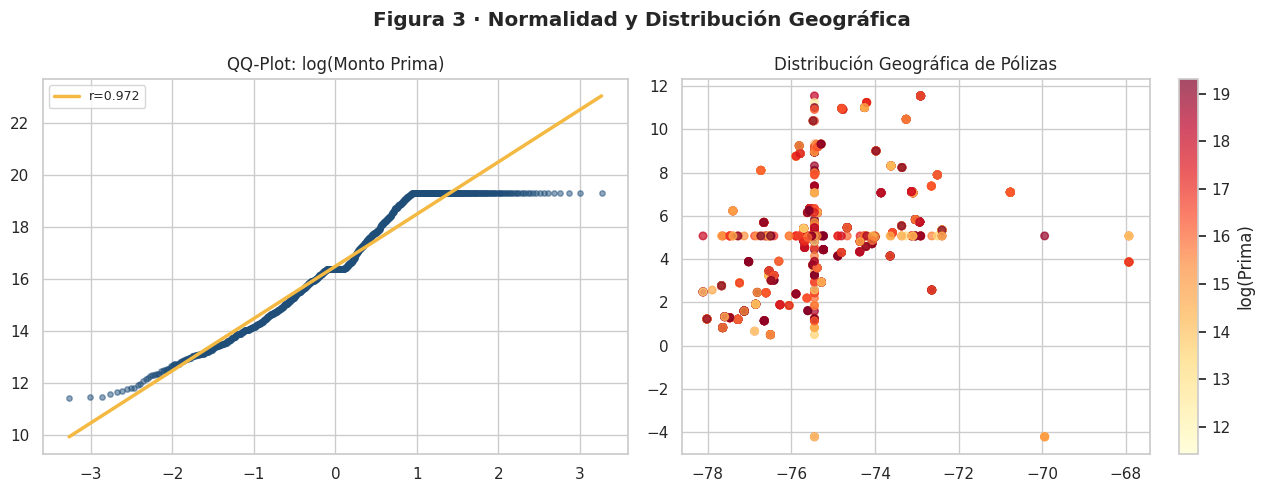

In [35]:
# 21. Figura 3: QQ-Plot y mapa geoespacial
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle("Figura 3 · Normalidad y Distribución Geográfica", fontweight="bold")

ax = axes[0]
log_p2 = np.log1p(dfLimpieza["monto_prima"])
(osm, osr), (slope, intercept, r_qq) = stats.probplot(log_p2, dist="norm")
ax.scatter(osm, osr, alpha=0.5, s=15, color=AZUL)
xqq = np.array([min(osm), max(osm)])
ax.plot(xqq, slope*xqq+intercept, color=AMARILLO, lw=2.5, label=f"r={r_qq:.3f}")
ax.set_title("QQ-Plot: log(Monto Prima)")
ax.legend(fontsize=9)

ax = axes[1]
if {"latitud","longitud"}.issubset(dfLimpieza.columns):
    sc = ax.scatter(dfLimpieza["longitud"], dfLimpieza["latitud"], c=log_p2, cmap="YlOrRd", alpha=0.7, s=30)
    plt.colorbar(sc, ax=ax, label="log(Prima)")
    ax.set_title("Distribución Geográfica de Pólizas")
else:
    ax.axis("off")

plt.tight_layout()
plt.savefig("fig3_normalidad_geo.png", dpi=150)
plt.show()


6. MATRIZ DE CORRELACIÓN
                         monto_prima  porcentaje_comision  monto_total_venta  \
monto_prima                     1.00                -0.04               0.72   
porcentaje_comision            -0.04                 1.00              -0.00   
monto_total_venta               0.72                -0.00               1.00   
ratio_siniestralidad           -0.16                -0.08              -0.22   
num_sinistros                  -0.02                -0.01               0.00   
monto_total_siniestros          0.48                 0.02               0.67   
antiguedad_meses                0.05                 0.04               0.08   
indice_riesgo_combinado         0.37                 0.02               0.49   

                         ratio_siniestralidad  num_sinistros  \
monto_prima                             -0.16          -0.02   
porcentaje_comision                     -0.08          -0.01   
monto_total_venta                       -0.22           0.00 

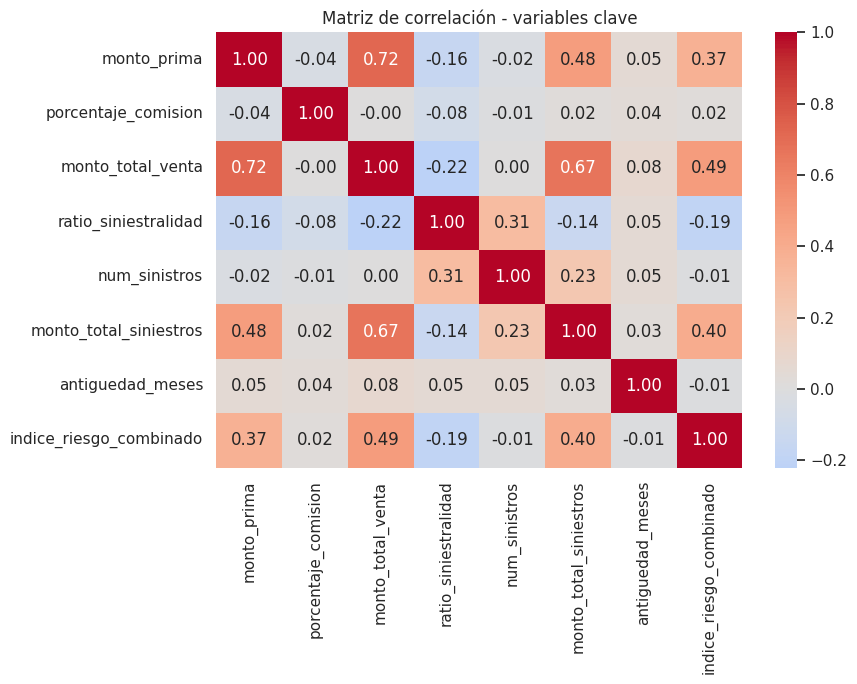

In [36]:
# 23. Correlaciones entre variables numéricas clave
# ------------------------------------------------------------
print("\n" + "="*60)
print("6. MATRIZ DE CORRELACIÓN")
print("="*60)
corr_vars = ['monto_prima', 'porcentaje_comision', 'monto_total_venta',
             'ratio_siniestralidad', 'num_sinistros', 'monto_total_siniestros',
             'antiguedad_meses', 'indice_riesgo_combinado']
corr_vars = [v for v in corr_vars if v in df.columns]
corr = df[corr_vars].corr().round(2)
print(corr)

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Matriz de correlación - variables clave')
plt.tight_layout()
plt.savefig('matriz_correlacion.png', dpi=150)
plt.show()

In [37]:
dfLimpieza.head()
dfLimpieza.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1274 entries, 0 to 1273
Data columns (total 50 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   id_venta                    1274 non-null   object        
 1   id_poliza                   1274 non-null   object        
 2   monto_prima                 1274 non-null   float64       
 3   porcentaje_comision         1274 non-null   float64       
 4   valor_impuesto              1274 non-null   float64       
 5   monto_total_venta           1274 non-null   float64       
 6   fecha_venta                 1274 non-null   datetime64[ns]
 7   tipo_ramo                   1274 non-null   object        
 8   fecha_inicio_poliza         1274 non-null   datetime64[ns]
 9   fecha_fin_poliza            1274 non-null   datetime64[ns]
 10  codigo_zona_sismica         1274 non-null   object        
 11  nivel_riesgo                1274 non-null   float64     

se realiza una ultima verificacion de la data que no contenga nulos,duplicados, espacios en blanco,etc. con eso los datos estarian listos para la division y hacer los modelos.

In [38]:
print('tamaño_empresa_num' in dfLimpieza.columns)

True


se confrirma que realmente si se creo la variable para la data limpia y poder implementar los modelos.

In [39]:
#14. Guardar dataset limpio todavia no se ha guardado hasta confirmar por favor
from pathlib import Path

carpeta_materia = ruta_dataset.parent.parent
ruta_salida = carpeta_materia / "DATA LIMPIA" / "dataset_polizas_limpio.xlsx"

dfLimpieza.to_excel(ruta_salida, index=False)
print("Dataset limpio guardado en:", ruta_salida)

Dataset limpio guardado en: /content/drive/MyDrive/GESTION_ ESTRATEGICA _PROYECTO_ MARSH_/DATA LIMPIA/dataset_polizas_limpio.xlsx


**Seleccion de Variables para el modelo**

In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

y = dfLimpieza["monto_prima"]

excluir = {
    "monto_prima": "es la variable objetivo",
    "valor_impuesto": "se calcula directamente de la prima (fuga de información)",
    "monto_total_venta": "prima + impuesto (fuga de información)",
    "log_monto_prima": "transformación de la prima (fuga de información)",
    "prima_diaria": "prima / duración de la póliza (fuga de información)",
    "id_venta": "identificador, sin poder predictivo",
    "id_poliza": "identificador, sin poder predictivo",
    "fecha_venta": "fecha (resumida en año, mes, trimestre y antigüedad)",
    "fecha_inicio_poliza": "fecha",
    "fecha_fin_poliza": "fecha",
    "codigo_zona_sismica": "código con muchas categorías",
    "codigo_divipola": "código con muchas categorías",
    "ciudad": "demasiadas categorías (se usa departamento)",
    "tipos_sinistro": "texto con muchas combinaciones",
}
excluir = {c: m for c, m in excluir.items() if c in dfLimpieza.columns}
display(pd.DataFrame({"Variable excluida": list(excluir), "Motivo": list(excluir.values())}))

candidatas = [c for c in dfLimpieza.columns if c not in excluir]
X = dfLimpieza[candidatas]
print(f"Variables candidatas: {len(candidatas)}")
print("NaN en y:", y.isna().sum())

,Variable excluida,Motivo
0,monto_prima,es la variable objetivo
1,valor_impuesto,se calcula directamente de la prima (fuga de i...
2,monto_total_venta,prima + impuesto (fuga de información)
3,log_monto_prima,transformación de la prima (fuga de información)
4,prima_diaria,prima / duración de la póliza (fuga de informa...
5,id_venta,"identificador, sin poder predictivo"
6,id_poliza,"identificador, sin poder predictivo"
7,fecha_venta,"fecha (resumida en año, mes, trimestre y antig..."
8,fecha_inicio_poliza,fecha
9,fecha_fin_poliza,fecha


Variables candidatas: 36
NaN en y: 0


**División train/test (80 % / 20 %)**

In [41]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42    # sin stratify: el objetivo es continuo
)
print(f"Entrenamiento: {X_train.shape[0]} filas")
print(f"Prueba       : {X_test.shape[0]} filas")

print("\nmonto_prima en TRAIN:"); print(y_train.describe().round(0))
print("\nmonto_prima en TEST:");  print(y_test.describe().round(0))

Entrenamiento: 1019 filas
Prueba       : 255 filas

monto_prima en TRAIN:
count         1019.0
mean      66565478.0
std       92843542.0
min          92223.0
25%        2770568.0
50%       13034790.0
75%       99959779.0
max      242935773.0
Name: monto_prima, dtype: float64

monto_prima en TEST:
count          255.0
mean      64938129.0
std       90489391.0
min          97138.0
25%        3240634.0
50%       13034790.0
75%       96436656.0
max      242935773.0
Name: monto_prima, dtype: float64


**Selección de variables (solo con train)**



In [49]:

numericas_cand   = X_train.select_dtypes(include="number").columns.tolist()
categoricas_cand = [c for c in X_train.columns if c not in numericas_cand]

# Variables constantes no aportan información
constantes = [c for c in numericas_cand if X_train[c].nunique() <= 1]

# Correlación de cada numérica con la prima
corr_obj = X_train[numericas_cand].apply(lambda s: s.corr(y_train))
print("Correlación de Pearson con monto_prima (train):")
display(corr_obj.sort_values(key=abs, ascending=False).round(3).to_frame("correlación"))

# Redundancia entre predictoras (|r| >= 0.90)
corr_pred = X_train[numericas_cand].corr().abs()
a_quitar = {}
for i, c1 in enumerate(numericas_cand):
    for c2 in numericas_cand[i + 1:]:
        if corr_pred.loc[c1, c2] >= 0.90:
            perdedor = c1 if abs(corr_obj[c1]) < abs(corr_obj[c2]) else c2
            ganador  = c2 if perdedor == c1 else c1
            a_quitar[perdedor] = f"redundante con {ganador} (r = {corr_pred.loc[c1, c2]:.2f})"

print("\nNuméricas que se quitan por redundancia o por ser constantes:")
for c, m in a_quitar.items():
    print(f"  - {c}: {m}")
for c in constantes:
    print(f"  - {c}: constante")

numericas   = [c for c in numericas_cand if c not in a_quitar and c not in constantes]
categoricas = categoricas_cand

# Separación de las categóricas: diferencia entre la categoría de mayor y menor prima promedio
train_con_y = X_train[categoricas].copy()
train_con_y["monto_prima"] = y_train.values
distancias = {}
for col in categoricas:
    medias = train_con_y.groupby(col, observed=True)["monto_prima"].mean()
    distancias[col] = medias.max() - medias.min()
print("\nSeparación de la prima entre categorías (mayor es más informativa):")
print(pd.Series(distancias).sort_values(ascending=False).round(0).to_string())

print(f"\nVariables numéricas que entran al modelo ({len(numericas)}): {numericas}")
print(f"Variables categóricas que entran al modelo ({len(categoricas)}): {categoricas}")

Correlación de Pearson con monto_prima (train):


,correlación
tamaño_empresa_num,0.729
suma_asegurada_estimada,0.650
nivel_riesgo,0.606
monto_total_siniestros,0.512
monto_total_pagado,0.473
monto_promedio_sinistro,0.464
indice_riesgo_combinado,0.455
ratio_siniestralidad,-0.294
nivel_riesgo_sismico,0.145
ratio_aprobacion_sinistros,0.107



Numéricas que se quitan por redundancia o por ser constantes:
  - mes_venta: redundante con trimestre_venta (r = 0.97)

Separación de la prima entre categorías (mayor es más informativa):
departamento        232895968.0
tamaño_empresa      210690542.0
sector_economico     90856504.0
tipo_sector          87943453.0
aseguradora          84153234.0
tipo_ramo            54131826.0
estado_poliza        27952749.0

Variables numéricas que entran al modelo (28): ['porcentaje_comision', 'nivel_riesgo', 'nivel_riesgo_sismico', 'latitud', 'longitud', 'riesgo_sector', 'num_sinistros', 'monto_total_siniestros', 'monto_total_pagado', 'sinistros_aprobados', 'sinistros_rechazados', 'duracion_poliza_dias', 'ratio_siniestralidad', 'anio_venta', 'tiene_sinistro', 'tamaño_empresa_num', 'antiguedad_meses', 'trimestre_venta', 'es_temporada_alta', 'ratio_aprobacion_sinistros', 'monto_promedio_sinistro', 'indice_riesgo_combinado', 'num_tipos_sinistro', 'es_renovacion', 'es_cancelada', 'suma_asegurada_estima

**Pipeline de preprocesamiento**

In [50]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

rama_numerica = Pipeline([
    ("imputar", SimpleImputer(strategy="median")),
    ("escalar", StandardScaler()),
])
rama_categorica = Pipeline([
    ("imputar", SimpleImputer(strategy="most_frequent")),
    ("codificar", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocesador = ColumnTransformer([
    ("num", rama_numerica, numericas),
    ("cat", rama_categorica, categoricas),
])

X_train_prep = preprocesador.fit_transform(X_train)      # ajusta SOLO con train
X_test_prep  = preprocesador.transform(X_test)           # aplica lo aprendido en train

nombres = preprocesador.get_feature_names_out()
print(f"X_train: {X_train.shape} -> {X_train_prep.shape}")
print(f"X_test : {X_test.shape} -> {X_test_prep.shape}")
print(f"Columnas tras preparar: {len(nombres)}")
print("NaN en train:", int(np.isnan(X_train_prep).sum()), "| NaN en test:", int(np.isnan(X_test_prep).sum()))


X_train: (1019, 36) -> (1019, 139)
X_test : (255, 36) -> (255, 139)
Columnas tras preparar: 139
NaN en train: 0 | NaN en test: 0


**ENTRENAMIENTO E IMPLEMENTACION DE MODELO DE PREDICCION**

In [51]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.dummy import DummyRegressor

flujo_lineal = Pipeline([("preparar", preprocesador), ("modelo", LinearRegression())])
flujo_arbol  = Pipeline([("preparar", preprocesador), ("modelo", DecisionTreeRegressor(random_state=42))])
flujo_arbol5 = Pipeline([("preparar", preprocesador), ("modelo", DecisionTreeRegressor(max_depth=5, random_state=42))])
modelo_base  = DummyRegressor(strategy="mean")

modelos = {
    "Base (promedio)": modelo_base,
    "Regresión lineal": flujo_lineal,
    "Árbol sin tope": flujo_arbol,
    "Árbol max_depth=5": flujo_arbol5,
}
for nombre, m in modelos.items():
    m.fit(X_train, y_train)
print("Modelos entrenados con TRAIN.")


Modelos entrenados con TRAIN.


**Métricas en train y test**

,MAE train,RMSE train,R2 train,MAE test,RMSE test,R2 test
Modelo,,,,,,
Base (promedio),"77,955,957.885","92,797,974.765",0.000,"76,040,571.627","90,326,446.978",-0.000
Regresión lineal,"32,457,905.311","48,939,839.769",0.722,"40,365,504.547","60,873,972.840",0.546
Árbol sin tope,0.000,0.000,1.000,"17,977,620.190","58,668,579.930",0.578
Árbol max_depth=5,"10,143,507.130","28,653,695.566",0.905,"20,011,265.188","54,382,975.225",0.637


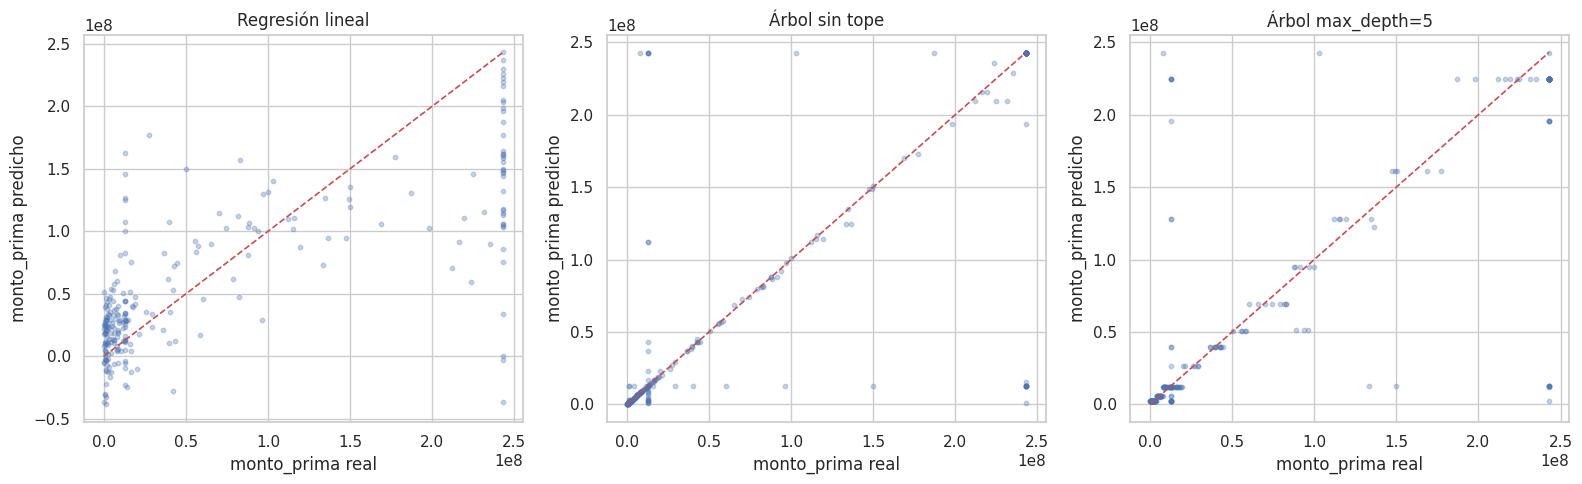

In [52]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

filas = []
for nombre, m in modelos.items():
    fila = {"Modelo": nombre}
    for conjunto, Xc, yc in [("train", X_train, y_train), ("test", X_test, y_test)]:
        pred = m.predict(Xc)
        fila[f"MAE {conjunto}"]  = mean_absolute_error(yc, pred)
        fila[f"RMSE {conjunto}"] = np.sqrt(mean_squared_error(yc, pred))
        fila[f"R2 {conjunto}"]   = r2_score(yc, pred)
    filas.append(fila)

tabla_metricas = pd.DataFrame(filas).set_index("Modelo")
pd.options.display.float_format = "{:,.3f}".format
display(tabla_metricas)
pd.reset_option("display.float_format")

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
limite = max(y_test.max(), flujo_lineal.predict(X_test).max())
for ax, nombre in zip(axes, ["Regresión lineal", "Árbol sin tope", "Árbol max_depth=5"]):
    pred = modelos[nombre].predict(X_test)
    ax.scatter(y_test, pred, s=10, alpha=0.3)
    ax.plot([0, limite], [0, limite], "r--", linewidth=1.2)      # predicción perfecta
    ax.set_xlabel("monto_prima real"); ax.set_ylabel("monto_prima predicho"); ax.set_title(nombre)
plt.tight_layout()
plt.show()

**IMPLEMENTACION MODELO SIMULACION  DE MONTECARLO**

simulación Montecarlo aplicada al portafolio de pólizas de Marsh Colombia.  
El objetivo es responder preguntas de negocio clave en la gestión del portafolio:

1. ¿Cuánta comisión puede generar el portafolio en un año bajo condiciones normales y de estrés?  
2. ¿Cuál es la probabilidad de que la siniestralidad supere el 100 % en un año?  
3. ¿Qué ocurre si las primas se incrementan en un 10 %?

La simulación utiliza parámetros estimados por ramo (tasa de cancelación, frecuencia y severidad de siniestros) y genera 5.000 escenarios anuales.  
Se comparan un escenario base, un escenario de estrés (+5 pp cancelación, +20 % frecuencia) y un escenario con incremento de primas (+10 %).

**Librerías y preparación de datos**

In [53]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

N_SIM = 5000
SEMILLA = 42
rng = np.random.default_rng(SEMILLA)

df = dfLimpieza.copy()
df["es_cancelada"] = pd.to_numeric(df["es_cancelada"], errors="coerce").fillna(0)
com = df["porcentaje_comision"].astype(float)
df["comision_frac"] = com / 100 if com.median() > 1 else com


**Estimación de parámetros por ramo**

In [54]:
con_sin = df[df["num_sinistros"] > 0].copy()
con_sin["sev"] = con_sin["monto_total_siniestros"] / con_sin["num_sinistros"]
sev_global = con_sin.loc[con_sin["sev"] > 0, "sev"]
sigma_g, _, scale_g = stats.lognorm.fit(sev_global, floc=0)
mu_g = np.log(scale_g)

ramos = {}
for ramo, g in df.groupby("tipo_ramo", observed=True):
    sev = (g.loc[g["num_sinistros"] > 0, "monto_total_siniestros"]
           / g.loc[g["num_sinistros"] > 0, "num_sinistros"])
    sev = sev[sev > 0]
    if len(sev) >= 10:
        sigma, _, scale = stats.lognorm.fit(sev, floc=0)
        mu = np.log(scale)
    else:
        mu, sigma = mu_g, sigma_g
    ramos[str(ramo)] = {
        "n": len(g),
        "p_cancel": g["es_cancelada"].mean(),
        "lam": g["num_sinistros"].mean(),
        "mu": mu, "sigma": sigma,
        "prima": g["monto_prima"].to_numpy(),
        "comision": (g["monto_prima"] * g["comision_frac"]).to_numpy(),
    }


**Función de simulación**

In [55]:
def simular(extra_cancelacion=0.0, factor_frecuencia=1.0, factor_prima=1.0, n_sim=N_SIM):
    prima_t = np.zeros(n_sim)
    comis_t = np.zeros(n_sim)
    sinis_t = np.zeros(n_sim)

    for r in ramos.values():
        p_activa = 1 - np.clip(r["p_cancel"] + extra_cancelacion, 0, 1)
        activas = rng.binomial(r["n"], p_activa, size=n_sim)

        filas = rng.integers(0, r["n"], size=activas.sum())
        sim_id = np.repeat(np.arange(n_sim), activas)
        prima_t += np.bincount(sim_id, weights=r["prima"][filas] * factor_prima, minlength=n_sim)
        comis_t += np.bincount(sim_id, weights=r["comision"][filas] * factor_prima, minlength=n_sim)

        n_sin = rng.poisson(r["lam"] * factor_frecuencia * activas)
        sev = rng.lognormal(r["mu"], r["sigma"], size=n_sin.sum())
        sim_id_s = np.repeat(np.arange(n_sim), n_sin)
        sinis_t += np.bincount(sim_id_s, weights=sev, minlength=n_sim)

    return pd.DataFrame({
        "prima_total": prima_t,
        "comision_total": comis_t,
        "siniestros_total": sinis_t,
        "ratio_siniestralidad": sinis_t / prima_t,
    })


**Escenarios y resumen**

In [56]:
base = simular()
estres = simular(extra_cancelacion=0.05, factor_frecuencia=1.20)
incremento_prima = simular(factor_prima=1.10)

def resumen(sim):
    out = {}
    for c in ["comision_total", "ratio_siniestralidad"]:
        out[c] = {
            "media": sim[c].mean(),
            "P5": sim[c].quantile(0.05),
            "P50": sim[c].quantile(0.50),
            "P95": sim[c].quantile(0.95),
        }
    return pd.DataFrame(out).T

print("\n=== ESCENARIO BASE ===")
display(resumen(base).round(3))
print("\n=== ESCENARIO DE ESTRÉS ===")
display(resumen(estres).round(3))
print("\n=== ESCENARIO INCREMENTO DE PRIMAS (+10 %) ===")
display(resumen(incremento_prima).round(3))

p_ratio = (estres["ratio_siniestralidad"] > 1).mean()
print(f"\nProbabilidad de siniestralidad > 100 % (estrés): {p_ratio:.1%}")



=== ESCENARIO BASE ===


,media,P5,P50,P95
comision_total,1.184615e+10,1.102500e+10,1.182765e+10,1.269401e+10
ratio_siniestralidad,1.158800e+01,9.774000e+00,1.142000e+01,1.382100e+01



=== ESCENARIO DE ESTRÉS ===


,media,P5,P50,P95
comision_total,1.119177e+10,1.035930e+10,1.118422e+10,1.204120e+10
ratio_siniestralidad,1.390300e+01,1.182300e+01,1.372900e+01,1.656200e+01



=== ESCENARIO INCREMENTO DE PRIMAS (+10 %) ===


,media,P5,P50,P95
comision_total,1.303959e+10,1.213297e+10,1.303442e+10,1.398054e+10
ratio_siniestralidad,1.051600e+01,8.917000e+00,1.037600e+01,1.253200e+01



Probabilidad de siniestralidad > 100 % (estrés): 100.0%


**Gráficos**

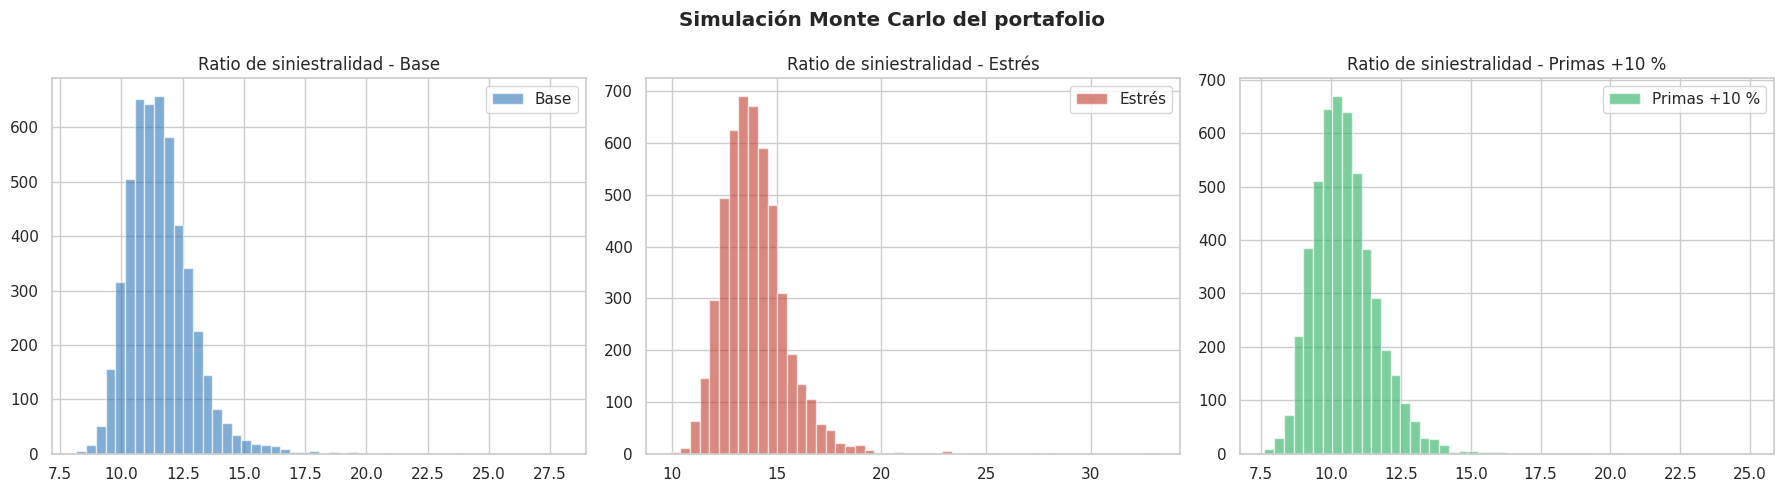

In [57]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Simulación Monte Carlo del portafolio", fontweight="bold")

for sim, nombre, color, eje in [
    (base, "Base", "#2E75B6", ax[0]),
    (estres, "Estrés", "#C0392B", ax[1]),
    (incremento_prima, "Primas +10 %", "#27AE60", ax[2])
]:
    eje.hist(sim["ratio_siniestralidad"], bins=50, alpha=0.6, label=nombre, color=color)
    eje.set_title(f"Ratio de siniestralidad - {nombre}")
    eje.legend()

plt.tight_layout()
plt.show()
